# Поиск ФИО и названия организаций в Excel

Работаем локально с Excel-файлами, выгруженными из CRM. Подключения к CRM нет.
Параметры — в разделе 1, работа с Excel — в разделе 8. Ячейки выполняются сверху вниз.
Результаты — таблицы и графики в ноутбуке. Отдельные JSON-отчёты не создаются.

## 1. Настройки

Ядро: Python 3.12 из `.venv`.

In [ ]:
from pathlib import Path
from datetime import datetime
import collections
import csv
import gc
import hashlib
import json
import os
import random
import re
import tarfile
import time
import unicodedata
from collections import Counter, defaultdict

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from razdel import tokenize
from seqeval.metrics.sequence_labeling import get_entities
from torch.utils.data import DataLoader, Dataset
from transformers import (
    AutoTokenizer, AutoModelForTokenClassification,
    AutoConfig, DataCollatorForTokenClassification,
    get_linear_schedule_with_warmup, set_seed,
)

In [ ]:
ROOT = Path.cwd()
MODEL_DIR = ROOT / "model"
DATA_PATH = ROOT / "data" / "collection3_v2.tar.gz"

RUN_COLLECTION3 = False
TRAIN_MODEL = False

# Работа с локальными Excel-выгрузками.
RUN_EXCEL = False
TRAIN_EXCEL = False
SEARCH_PARAMS = False
RUN_TEST = False
EXCEL_PATH = ROOT / "data" / "annotations_fixed.xlsx"
CURRENT_MODEL_DIR = ROOT / "runs/crm_20261026_124828_530079/finetuned/model"
EXCEL_SHEET = 1
TEXT_COLUMN = "Комментарий"
STATUS_COLUMN = "Статус"
ANNOTATION_COLUMN = "Разметка JSON"
EXCEL_EPOCHS = 5
EXCEL_LR = 2e-5
SEARCH_LRS = [1e-5, 2e-5, 5e-5]
SEARCH_EPOCHS = 10
SPLIT_SEED = 42
TRAIN_SEEDS = [42]  # Для проверки устойчивости: [42, 43, 44].

SEED = 42
MAX_LENGTH = 128
BATCH_SIZE = 2
ACCUMULATION = 8
EPOCHS = 5
LEARNING_RATES = [5e-5, 1e-4]
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

LABELS = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = dict(enumerate(LABELS))
KINDS = ("PER", "ORG")
MODEL_ID = "cointegrated/rubert-tiny2"
MODEL_REVISION = "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae"
DATA_SHA256 = "c57f5cfd33ca279b1f2aaa31ab260aecd15c0ac3f27a36d8571cca69e9fb8bbc"

torch.set_num_threads(2)
set_seed(SEED)
if TRAIN_MODEL and (not RUN_COLLECTION3 or RUN_EXCEL):
    raise ValueError("Обучение на Collection3 запускайте отдельно от Excel.")
if (TRAIN_EXCEL or SEARCH_PARAMS or RUN_TEST) and not RUN_EXCEL:
    raise ValueError("Сначала включите RUN_EXCEL.")

## 2. Подготовка данных

Общие функции нужны и для Excel. Collection3 — новости для исходного обучения;
он читается только при `RUN_COLLECTION3 = True`.

In [ ]:
def repair_bio(tags):
    result, previous, fixes = [], "O", 0
    for tag in tags:
        if tag.startswith("I-") and previous not in {"B-" + tag[2:], tag}:
            tag = "B-" + tag[2:]
            fixes += 1
        result.append(tag)
        previous = tag
    return result, fixes


def join_tokens(tokens):
    offsets, cursor = [], 0
    for token in tokens:
        offsets.append((cursor, cursor + len(token)))
        cursor += len(token) + 1
    return " ".join(tokens), offsets


def spans_from_tags(tags, offsets):
    return [(offsets[a][0], offsets[b][1], kind)
            for kind, a, b in get_entities(repair_bio(tags)[0]) if kind in KINDS]


def text_sample(text, column="", sample_id="inference"):
    words = list(tokenize(text))
    return {"id": sample_id, "text": text, "column": column,
            "tokens": [w.text for w in words], "offsets": [(w.start, w.stop) for w in words],
            "tags": ["O"] * len(words), "entities": []}

In [ ]:
def parse_conll(content, split):
    samples, tokens, tags, doc, fixed = [], [], [], -1, 0

    def flush():
        nonlocal tokens, tags, fixed
        if not tokens:
            return
        original, n = repair_bio(tags)
        target, _ = repair_bio([t if t[2:] in KINDS else "O" for t in original])
        text, offsets = join_tokens(tokens)
        samples.append({"id": f"{split}:{len(samples)}", "doc_id": f"{split}:{doc}",
                        "text": text, "column": "", "tokens": tokens, "offsets": offsets,
                        "tags": target, "entities": spans_from_tags(target, offsets)})
        fixed += n
        tokens, tags = [], []

    for line in content.splitlines():
        if not line.strip():
            flush()
        elif line.startswith("<DOCSTART>"):
            flush()
            doc += 1
        else:
            token, tag = line.rsplit(None, 1)
            if tag != "O" and tag not in {f"{p}-{k}" for p in ("B", "I") for k in (*KINDS, "LOC")}:
                raise ValueError(f"Неизвестная метка Collection3: {tag}")
            tokens.append(token)
            tags.append(tag)
    flush()
    return samples, fixed


def read_collection3(path):
    path = Path(path)
    if hashlib.sha256(path.read_bytes()).hexdigest() != DATA_SHA256:
        raise ValueError("Контрольная сумма Collection3 не совпадает.")
    raw, fixes = {}, {}
    with tarfile.open(path, "r:gz") as archive:
        for split, name in (("train", "train.txt"), ("validation", "valid.txt"), ("test", "test.txt")):
            with archive.extractfile(name) as stream:
                raw[split], fixes[split] = parse_conll(stream.read().decode("utf-8"), split)
    clean, removed, encountered = {}, {}, set()
    # Убираем повторы: сначала оставляем test, затем validation, затем train.
    for split in ("test", "validation", "train"):
        clean[split], removed[split] = [], 0
        for sample in raw[split]:
            key = tuple(sample["tokens"])
            if key in encountered:
                removed[split] += 1
            else:
                encountered.add(key)
                clean[split].append(sample)
    return clean, {"bio_fixes": fixes, "duplicates_removed": removed}

In [ ]:
if RUN_COLLECTION3:
    news, cleaning = read_collection3(DATA_PATH)
    summary = []
    for split in ("train", "validation", "test"):
        rows = news[split]
        summary.append({
            "Часть": split,
            "Текстов": len(rows),
            "Слов": sum(len(s["tokens"]) for s in rows),
            "PER": sum(k == "PER" for s in rows for _, _, k in s["entities"]),
            "ORG": sum(k == "ORG" for s in rows for _, _, k in s["entities"]),
        })
    display(pd.DataFrame(summary))
    display(pd.Series(cleaning, name="Количество").to_frame())

## 3. Токенизация

Метка ставится первой части слова. Длинные тексты делятся на окна без потери конца.

In [ ]:
class EncodedNER(Dataset):
    """Делим длинный текст на окна, не разрезая слова."""
    def __init__(self, samples, tokenizer, max_length=128, use_column=False):
        self.features, self.chunks = [], []
        self.normalization_replacements = 0
        for sample_index, sample in enumerate(samples):
            tokens = list(sample["tokens"])
            if not tokens:
                continue
            whole = tokenizer(tokens, is_split_into_words=True, add_special_tokens=False, truncation=False, verbose=False)
            counts = collections.Counter(whole.word_ids())
            missing = [i for i in range(len(tokens)) if not counts[i]]
            for i in missing:
                tokens[i] = tokenizer.unk_token
            self.normalization_replacements += len(missing)
            if missing:
                counts = collections.Counter(tokenizer(tokens, is_split_into_words=True,
                    add_special_tokens=False, truncation=False, verbose=False).word_ids())
            prefix = [w.text for w in tokenize(sample.get("column", ""))] + [":"] if use_column else []
            prefix_cost = len(tokenizer(prefix, is_split_into_words=True, add_special_tokens=False)["input_ids"]) if prefix else 0
            budget = max_length - tokenizer.num_special_tokens_to_add(pair=False) - prefix_cost
            if budget < 1:
                raise ValueError("Название колонки занимает всё окно: увеличьте max_length.")
            start = 0
            while start < len(tokens):
                end, used = start, 0
                while end < len(tokens) and used + counts[end] <= budget:
                    used += counts[end]
                    end += 1
                if end == start:
                    raise ValueError("Слово длиннее окна: увеличьте max_length.")
                encoded = tokenizer(prefix + tokens[start:end], is_split_into_words=True, truncation=False)
                previous, aligned = None, []
                for word in encoded.word_ids():
                    target = word is not None and word >= len(prefix) and word != previous
                    aligned.append(LABEL2ID[sample["tags"][start + word - len(prefix)]] if target else -100)
                    previous = word
                encoded["labels"] = aligned
                assert len(encoded["input_ids"]) <= max_length
                assert sum(t != -100 for t in aligned) == end - start
                self.features.append(dict(encoded))
                self.chunks.append((sample_index, start, end))
                start = end

    def __len__(self):
        return len(self.features)

    def __getitem__(self, index):
        return self.features[index]


def reassemble(chunk_predictions, dataset, samples):
    output = [[None] * len(s["tokens"]) for s in samples]
    assert len(chunk_predictions) == len(dataset)
    for tags, (index, start, end) in zip(chunk_predictions, dataset.chunks):
        assert len(tags) == end - start
        output[index][start:end] = tags
    assert all(None not in tags for tags in output)
    return [repair_bio(tags)[0] for tags in output]

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR, local_files_only=True, use_fast=True)
if RUN_COLLECTION3:
    example_data = EncodedNER([sample], tokenizer, MAX_LENGTH)
    feature = example_data[0]
    display(pd.DataFrame({
        "Токен": tokenizer.convert_ids_to_tokens(feature["input_ids"]),
        "Метка": [ID2LABEL[x] if x != -100 else "пропускаем" for x in feature["labels"]],
    }).head(25))

## 4. Метрики

Precision — точность находок, recall — полнота, F1 — их баланс.
Для маскировки смотрим также покрытие символов и долю текстов с остатками сущностей.

In [ ]:
def ratio(numerator, denominator):
    return numerator / denominator if denominator else 0.0


def entity_metrics(tp, gold, predicted):
    return dict(precision=ratio(tp, predicted), recall=ratio(tp, gold), f1=ratio(2 * tp, gold + predicted))


def score_spans(samples, predictions):
    if len(samples) != len(predictions):
        raise ValueError("Разное число примеров и предсказаний.")
    totals = {kind: Counter() for kind in KINDS}
    for sample, found in zip(samples, predictions):
        gold, found = set(sample["entities"]), set(found)
        masked = {i for a, b, _ in found for i in range(a, b) if not sample["text"][i].isspace()}
        for kind, counts in totals.items():
            g, p = ({entity for entity in group if entity[2] == kind} for group in (gold, found))
            chars = {i for a, b, _ in g for i in range(a, b) if not sample["text"][i].isspace()}
            counts.update(tp=len(g & p), gold=len(g), predicted=len(p), chars=len(chars),
                          covered=len(chars & masked), positive_cells=int(bool(g)), residual_cells=int(bool(chars - masked)))
    metrics = {}
    for kind, counts in totals.items():
        values = entity_metrics(counts["tp"], counts["gold"], counts["predicted"])
        values.update(support=counts["gold"], positive_cells=counts["positive_cells"],
                      char_coverage=ratio(counts["covered"], counts["chars"]),
                      residual_cell_rate=ratio(counts["residual_cells"], counts["positive_cells"]))
        metrics.update({f"{kind}_{key}": value for key, value in values.items()})
    metrics.update(entity_metrics(*(sum(counts[key] for counts in totals.values()) for key in ("tp", "gold", "predicted"))))
    return dict(metrics, macro_f1=sum(metrics[f"{kind}_f1"] for kind in KINDS) / len(KINDS))


def unseen_recall(samples, predictions, training_samples, dictionary=()):
    names = {kind: {s["text"][a:b].casefold() for s in training_samples for a, b, k in s["entities"] if k == kind}
             for kind in KINDS}
    known, rows = {name.casefold() for name in dictionary}, []
    for kind in KINDS:
        seen = names[kind] | known
        unseen = [(a, b, k) in set(found) for sample, found in zip(samples, predictions)
                  for a, b, k in sample["entities"]
                  if k == kind and sample["text"][a:b].casefold() not in seen]
        rows.append(dict(label=kind, support=len(unseen), exact_recall=ratio(sum(unseen), len(unseen)) if unseen else None))
    return rows

In [ ]:
def decode_predictions(ids, labels, dataset, samples):
    chunks = [[ID2LABEL[int(p)] for p, gold in zip(row, targets) if gold != -100]
              for row, targets in zip(ids, labels)]
    return [spans_from_tags(tags, sample["offsets"])
            for tags, sample in zip(reassemble(chunks, dataset, samples), samples)]


def predict_model(model, tokenizer, samples, max_length=128, batch_size=16, use_column=False, dataset=None, return_loss=False):
    dataset = dataset if dataset is not None else EncodedNER(samples, tokenizer, max_length, use_column)
    ids, labels = [], []
    loss_sum, token_count = 0.0, 0
    model.eval()
    with torch.inference_mode():
        for batch in DataLoader(dataset, batch_size=batch_size, collate_fn=DataCollatorForTokenClassification(tokenizer)):
            targets = batch.pop("labels")
            labels.extend(targets.numpy())
            logits = model(**{key: value.to(model.device) for key, value in batch.items()}).logits
            ids.extend(logits.argmax(-1).cpu().numpy())
            if return_loss:
                loss_sum += torch.nn.functional.cross_entropy(
                    logits.reshape(-1, logits.shape[-1]), targets.to(model.device).reshape(-1),
                    ignore_index=-100, reduction="sum").item()
                token_count += int((targets != -100).sum())
    predictions = decode_predictions(ids, labels, dataset, samples)
    return (predictions, loss_sum / max(1, token_count)) if return_loss else predictions


def check_model_labels(model):
    if model.config.id2label != ID2LABEL:
        raise ValueError("Нужен checkpoint PER+ORG с пятью метками; ORG-only не подходит.")


def load_model(path, device="cpu", offline=True, **options):
    model = AutoModelForTokenClassification.from_pretrained(path, local_files_only=offline, trust_remote_code=False, **options)
    check_model_labels(model)
    return model.to(device)


def model_settings(path):
    config = AutoConfig.from_pretrained(path, local_files_only=True)
    settings = {"max_length": getattr(config, "ner_max_length", 128),
                "use_column": getattr(config, "ner_use_column", False)}
    # Совместимость с ранее обученными весами.
    old_settings = Path(path) / "preprocessing.json"
    if old_settings.is_file():
        settings.update(json.loads(old_settings.read_text()))
    return settings

def evaluate_checkpoint(path, samples, device="cpu", batch_size=16):
    model = load_model(path, device)
    try:
        tokenizer = AutoTokenizer.from_pretrained(path, local_files_only=True, use_fast=True)
        settings = model_settings(path)
        return score_spans(samples, predict_model(model, tokenizer, samples, batch_size=batch_size,
                            **{key: settings[key] for key in ("max_length", "use_column")}))
    finally:
        del model
        release_model()


def synchronize(device):
    if str(device).startswith("cuda"):
        torch.cuda.synchronize()
    elif str(device) == "mps":
        torch.mps.synchronize()


def release_model():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()

In [ ]:
def show_metrics(results, title):
    table = pd.DataFrame(results).T
    columns = ["PER_precision", "PER_recall", "PER_f1", "ORG_precision", "ORG_recall",
               "ORG_f1", "f1", "macro_f1", "PER_char_coverage", "ORG_char_coverage",
               "PER_residual_cell_rate", "ORG_residual_cell_rate"]
    display(table[columns].round(4))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    plots = [(["PER_f1", "ORG_f1", "macro_f1"], "F1", ["PER", "ORG", "Macro"]),
             (["PER_char_coverage", "ORG_char_coverage"], "Закрыто символов", ["PER", "ORG"]),
             (["PER_residual_cell_rate", "ORG_residual_cell_rate"], "Текстов с пропусками", ["PER", "ORG"])]
    for ax, (keys, label, names) in zip(axes, plots):
        data = table[keys].copy()
        data.columns = names
        data.plot.bar(ax=ax, rot=25)
        ax.set(title=label, xlabel="", ylim=(0, 1.05))
        ax.grid(axis="y", alpha=0.2)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def show_training(history, title="Дообучение на Excel"):
    history = pd.DataFrame(history)
    epoch_table = history.groupby("epoch", as_index=False).last()
    columns = ["epoch", "loss", "eval_loss", "eval_PER_f1", "eval_ORG_f1", "eval_macro_f1"]
    names = ["Эпоха", "Train loss", "Validation loss", "PER F1", "ORG F1", "Macro F1"]
    display(epoch_table[columns].set_axis(names, axis=1).round(4))
    best_epoch = epoch_table.loc[epoch_table["eval_macro_f1"].idxmax(), "epoch"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for key, label in [("loss", "Train"), ("eval_loss", "Validation")]:
        if key in history:
            rows = history.dropna(subset=[key])
            axes[0].plot(rows["epoch"], rows[key], marker="o", label=label)
    for key, label in [("eval_PER_f1", "PER"), ("eval_ORG_f1", "ORG"), ("eval_macro_f1", "Macro")]:
        rows = history.dropna(subset=[key])
        axes[1].plot(rows["epoch"], rows[key], marker="o", label=label)
    axes[0].set(title="Loss", xlabel="Эпоха")
    axes[1].set(title="F1 на validation", xlabel="Эпоха", ylim=(0, 1.05))
    for ax in axes:
        ax.axvline(best_epoch, color="gray", linestyle="--", label=f"Лучшая эпоха: {best_epoch:g}")
        ax.set_xticks(epoch_table["epoch"])
        ax.legend()
        ax.grid(alpha=0.2)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

## 5. Обучение

После каждой эпохи считаем validation. Сохраняем веса лучшей эпохи по macro F1.
Метрики и история остаются в переменных ноутбука.

In [ ]:
def token_classification_loss(outputs, labels, num_items_in_batch=None, class_weights=None):
    """Сумма взвешенных ошибок / число целевых токенов всего накопленного batch."""
    logits = outputs.logits
    denominator = (labels != -100).sum() if num_items_in_batch is None else num_items_in_batch
    denominator = torch.as_tensor(denominator, device=logits.device).clamp_min(1)
    return torch.nn.functional.cross_entropy(
        logits.reshape(-1, logits.shape[-1]), labels.reshape(-1),
        weight=None if class_weights is None else logits.new_tensor(class_weights),
        ignore_index=-100, reduction="sum") / denominator

In [ ]:
def train_experiment(name, initial_model, tokenizer, training, validation, run_dir,
                     device="cpu", lr=2e-5, epochs=5, seed=42, max_length=128,
                     batch_size=2, use_column=False, from_base=False, offline=True,
                     gradient_accumulation_steps=8, early_stopping_patience=2,
                     class_weights=None, selection_metric="macro_f1"):
    set_seed(seed)
    if min(epochs, batch_size, gradient_accumulation_steps) < 1:
        raise ValueError("Эпохи и размеры batch должны быть положительными.")
    options = {"revision": MODEL_REVISION, "num_labels": len(LABELS),
               "id2label": ID2LABEL, "label2id": LABEL2ID} if from_base else {}
    model = load_model(initial_model, device, offline=offline, **options)
    train_data = EncodedNER(training, tokenizer, max_length, use_column)
    valid_data = EncodedNER(validation, tokenizer, max_length, use_column)
    if not len(train_data) or not len(valid_data):
        raise ValueError("Нужны непустые train и validation.")
    collator = DataCollatorForTokenClassification(tokenizer)
    group_size = batch_size * gradient_accumulation_steps
    steps_per_epoch = (len(train_data) + group_size - 1) // group_size
    total_steps = steps_per_epoch * epochs
    no_decay = ("bias", "LayerNorm.weight")
    parameters = [
        {"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)], "weight_decay": 0.01},
        {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)], "weight_decay": 0.0},
    ]
    optimizer = torch.optim.AdamW(parameters, lr=lr)
    scheduler = get_linear_schedule_with_warmup(optimizer, (total_steps + 9) // 10, total_steps)
    weights = None if class_weights is None else [class_weights.get(label, 1.0) for label in LABELS]
    history, best_state, best_metrics = [], None, None
    best_score = float("inf") if selection_metric.endswith("residual_cell_rate") else -float("inf")
    bad_epochs, step = 0, 0
    started = time.perf_counter()

    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(train_data)).tolist()
        loss_sum, token_count = 0.0, 0
        for start in range(0, len(order), group_size):
            indices = order[start:start + group_size]
            targets = sum(sum(label != -100 for label in train_data[i]["labels"]) for i in indices)
            optimizer.zero_grad()
            for offset in range(0, len(indices), batch_size):
                batch = collator([train_data[i] for i in indices[offset:offset + batch_size]])
                labels = batch.pop("labels").to(device)
                output = model(**{key: value.to(device) for key, value in batch.items()})
                loss = token_classification_loss(output, labels, targets, weights)
                loss.backward()
                loss_sum += loss.item() * targets
            token_count += targets
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            step += 1

        predictions, valid_loss = predict_model(model, tokenizer, validation, dataset=valid_data,
                                                batch_size=batch_size, return_loss=True)
        metrics = score_spans(validation, predictions)
        history.append({"epoch": epoch, "step": step, "loss": loss_sum / max(1, token_count),
                        "eval_loss": valid_loss, **{"eval_" + k: v for k, v in metrics.items()}})
        score = metrics[selection_metric]
        improved = score < best_score if selection_metric.endswith("residual_cell_rate") else score > best_score
        if improved:
            best_score, best_metrics, bad_epochs = score, metrics, 0
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            bad_epochs += 1
        if early_stopping_patience is not None and bad_epochs >= early_stopping_patience:
            break

    model.load_state_dict(best_state)
    model.config.ner_max_length = max_length
    model.config.ner_use_column = use_column
    final = Path(run_dir) / name / "model"
    final.mkdir(parents=True, exist_ok=False, mode=0o700)
    model.save_pretrained(final)
    tokenizer.save_pretrained(final)
    result = {"method": name, "model_path": str(final.resolve()), "lr": lr, "seed": seed,
              "train_loss": history[-1]["loss"], "completed_epochs": len(history),
              "optimizer_steps": step, "train_seconds": time.perf_counter() - started,
              "best_validation_score": best_score, "best_validation_macro_f1": best_metrics["macro_f1"],
              "validation": best_metrics, "training_history": history}
    del model, optimizer, best_state
    release_model()
    return result

### Collection3

Ниже сохранены результаты исходного обучения на новостях от 18.10.2026.

In [ ]:
# Сохранённые результаты Collection3: одна схема для обоих экспериментов.
experiment_columns = ['method', 'lr', 'train_loss', 'completed_epochs', 'best_validation_macro_f1', 'PER_f1', 'ORG_f1']
experiments = [dict(zip(experiment_columns, values)) for values in [('tiny2_lr5e-05', 5e-05, 0.09322568633915049, 5.0, 0.909647468246966, 0.9616198247204594, 0.8576751117734724), ('tiny2_lr1e-04', 0.0001, 0.06827751889165525, 5.0, 0.9207569846657913, 0.9687594783136184, 0.8727544910179641)]]
histories = {}
histories['tiny2_lr5e-05'] = dict(
    loss_steps=list(range(50, 2801, 50)), epoch=list(range(1, 6)),
    loss=[
        1.4603, 0.7952, 0.4075, 0.26, 0.2073, 0.1365, 0.1321, 0.0924, 0.0852, 0.0831,
        0.0846, 0.0693, 0.0686, 0.0561, 0.0581, 0.0504, 0.0598, 0.0524, 0.0494, 0.0539,
        0.0584, 0.0478, 0.0485, 0.0342, 0.0359, 0.0327, 0.0345, 0.0366, 0.038, 0.0313,
        0.0265, 0.0332, 0.0335, 0.0327, 0.0228, 0.0239, 0.0236, 0.0244, 0.0249, 0.0234,
        0.0252, 0.0222, 0.0261, 0.0221, 0.021, 0.0177, 0.0193, 0.0182, 0.0208, 0.0193,
        0.0246, 0.0174, 0.0179, 0.019, 0.0204, 0.0173,
    ],
    f1=[
        0.8370171109754443, 0.8943863463762358, 0.9069270208478257, 0.909647468246966, 0.909645782188115,
    ],
)
histories['tiny2_lr1e-04'] = dict(
    loss_steps=list(range(50, 2801, 50)), epoch=list(range(1, 6)),
    loss=[
        1.332, 0.5279, 0.2759, 0.1655, 0.1447, 0.0963, 0.102, 0.0718, 0.0681, 0.0667,
        0.0695, 0.0532, 0.0479, 0.0396, 0.0405, 0.0396, 0.0422, 0.0368, 0.0357, 0.0395,
        0.047, 0.0364, 0.033, 0.0215, 0.0211, 0.0192, 0.0198, 0.023, 0.0217, 0.0183,
        0.0163, 0.0226, 0.0224, 0.0186, 0.011, 0.0108, 0.0132, 0.0142, 0.0126, 0.0142,
        0.0124, 0.0093, 0.0132, 0.0094, 0.0104, 0.0078, 0.007, 0.0065, 0.0104, 0.0064,
        0.008, 0.0064, 0.0072, 0.0091, 0.0081, 0.0091,
    ],
    f1=[
        0.8752978663588482, 0.906196567058077, 0.9153505135185889, 0.9207569846657913, 0.9192563265955753,
    ],
)

In [15]:
active_model_dir = MODEL_DIR
if TRAIN_MODEL:
    # Для этого режима нужен интернет: скачиваются исходные веса RuBERT-tiny2.
    run_dir = ROOT / "runs" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    run_dir.mkdir(parents=True, exist_ok=False)
    base_tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REVISION, use_fast=True)
    common = dict(
        tokenizer=base_tokenizer, run_dir=run_dir, device=DEVICE,
        seed=SEED, max_length=MAX_LENGTH, batch_size=BATCH_SIZE,
        offline=False,
    )

    pool = [s for s in news["train"] if s["entities"] and 4 <= len(s["tokens"]) <= 32]
    random.Random(SEED).shuffle(pool)
    small, used = [], set()
    for kind in KINDS:
        chosen = [s for s in pool if s["id"] not in used
                  and any(k == kind for _, _, k in s["entities"])][:16]
        small.extend(chosen)
        used.update(s["id"] for s in chosen)
    if len(small) != 32:
        raise ValueError("Не хватило примеров для проверки обучения.")
    sanity = train_experiment(
        "sanity", MODEL_ID, training=small, validation=small,
        lr=1e-3, epochs=20, from_base=True, **common,
    )
    if sanity["validation"]["macro_f1"] < 0.8 or any(sanity["validation"][f"{k}_f1"] == 0 for k in KINDS):
        raise RuntimeError("Модель не запомнила маленькую выборку. Нужно проверить обучение.")

    experiments, histories = [], {}
    for lr in LEARNING_RATES:
        result = train_experiment(
            f"tiny2_lr{lr:.0e}", MODEL_ID,
            training=news["train"], validation=news["validation"],
            lr=lr, epochs=EPOCHS, from_base=True,
            gradient_accumulation_steps=ACCUMULATION,
            early_stopping_patience=2, **common,
        )
        experiments.append({
            **{k: result[k] for k in ["method", "lr", "train_loss", "completed_epochs",
                                     "best_validation_macro_f1"]},
            "PER_f1": result["validation"]["PER_f1"],
            "ORG_f1": result["validation"]["ORG_f1"],
            "model_path": result["model_path"],
        })
        history = result["training_history"]
        valid = [r for r in history if "eval_macro_f1" in r]
        histories[result["method"]] = {
            "loss_steps": [r["step"] for r in history if "loss" in r],
            "loss": [r["loss"] for r in history if "loss" in r],
            "epoch": [r["epoch"] for r in valid],
            "f1": [r["eval_macro_f1"] for r in valid],
        }
    best = max(experiments, key=lambda r: r["best_validation_macro_f1"])
    active_model_dir = Path(best["model_path"])

display(pd.DataFrame(experiments).drop(columns="model_path", errors="ignore").round(4))

,method,lr,train_loss,completed_epochs,best_validation_macro_f1,PER_f1,ORG_f1
0,tiny2_lr5e-05,0.0000,0.0932,5.0,0.9096,0.9616,0.8577
1,tiny2_lr1e-04,0.0001,0.0683,5.0,0.9208,0.9688,0.8728


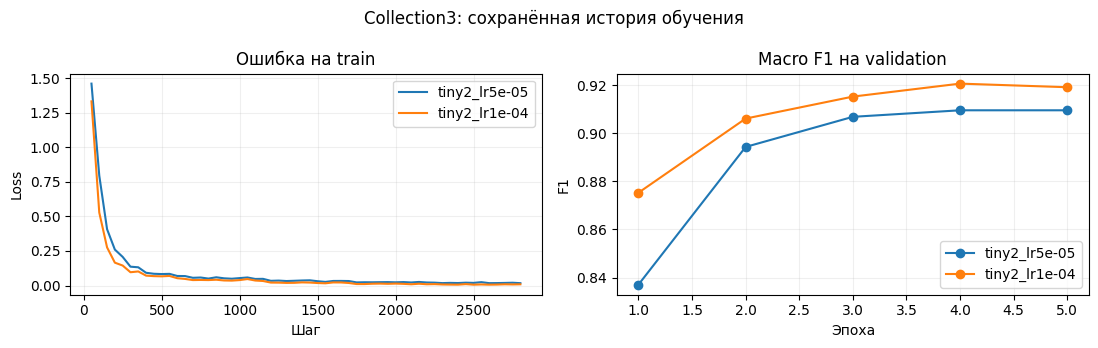

In [16]:
# Сохранённая история Collection3 доступна без чтения датасета.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
fig.suptitle("Collection3: " + ("текущее обучение" if TRAIN_MODEL else "сохранённая история обучения"))
for name, history in histories.items():
    axes[0].plot(history["loss_steps"], history["loss"], label=name)
    axes[1].plot(history["epoch"], history["f1"], marker="o", label=name)
axes[0].set(title="Ошибка на train", xlabel="Шаг", ylabel="Loss")
axes[1].set(title="Macro F1 на validation", xlabel="Эпоха", ylabel="F1")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
plt.close(fig)

## 6. Test Collection3

Это новости, а не Excel-выгрузки.

,F1
PER,0.9724
ORG,0.8718


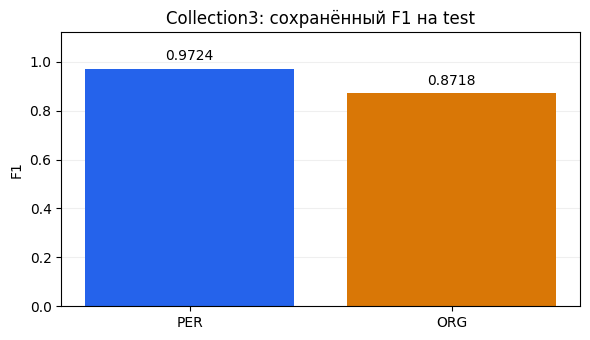

In [17]:
settings = model_settings(active_model_dir)
tokenizer = AutoTokenizer.from_pretrained(active_model_dir, local_files_only=True, use_fast=True)
model = load_model(active_model_dir, "cpu")
predict_options = dict(max_length=settings["max_length"], use_column=settings["use_column"], batch_size=1)

if RUN_COLLECTION3:
    # Прогреваем модель, чтобы первый вызов не искажал время.
    predict_model(model, tokenizer, news["test"][:2], **predict_options)
    started = time.perf_counter()
    predictions = predict_model(model, tokenizer, news["test"], **predict_options)
    seconds = time.perf_counter() - started
    metrics = score_spans(news["test"], predictions)

    display(pd.DataFrame([
        {"Класс": k, "Precision": metrics[f"{k}_precision"],
         "Recall": metrics[f"{k}_recall"], "F1": metrics[f"{k}_f1"],
         "Сущностей": metrics[f"{k}_support"],
         "Закрыто символов": metrics[f"{k}_char_coverage"],
         "Текстов с пропусками": metrics[f"{k}_residual_cell_rate"]}
        for k in KINDS
    ]).round(4))
    display(pd.Series({"Macro F1": metrics["macro_f1"], "Секунд": seconds,
                       "Текстов/с": len(predictions) / seconds}).round(4).to_frame("Значение"))
else:
    archived_test = pd.Series({"PER": 0.9724, "ORG": 0.8718}, name="F1")
    display(archived_test.to_frame())
    fig, ax = plt.subplots(figsize=(6, 3.5))
    bars = ax.bar(archived_test.index, archived_test.values, color=["#2563eb", "#d97706"])
    ax.bar_label(bars, fmt="%.4f", padding=4)
    ax.set(title="Collection3: сохранённый F1 на test", ylabel="F1", ylim=(0, 1.12))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

In [ ]:
if RUN_COLLECTION3:
    display(pd.DataFrame(unseen_recall(news["test"], predictions, news["train"])).round(4))

## 7. Примеры ошибок на новостях

In [ ]:
def show_entities(text, entities):
    return "; ".join(f"{text[a:b]} ({kind})" for a, b, kind in sorted(entities)) or "—"

if RUN_COLLECTION3:
    errors = []
    for sample, predicted in zip(news["test"], predictions):
        gold, found = set(sample["entities"]), set(predicted)
        if gold != found:
            errors.append({
                "Текст": sample["text"],
                "Пропущено": show_entities(sample["text"], gold - found),
                "Лишнее или другие границы": show_entities(sample["text"], found - gold),
            })
    with pd.option_context("display.max_colwidth", 120):
        display(pd.DataFrame(errors).head(8))

## 8. Excel-выгрузки

Нужны колонки `Комментарий`, `Статус`, `Разметка JSON`. Берём строки со статусом `проверено`.
Разметка уже хранится в ячейках Excel: `start`, `end`, `label`, `text`; без сущностей — `[]`.
Исходные тексты здесь не показываем.

### Результаты дообучения на Excel

Запуск от 26.10.2026: сравнение до/после на test и ход обучения по эпохам.

,Значение
Эпох,5.0000
Лучшая эпоха,4.0000
Validation macro F1,0.6902
"Время обучения, с",108.2356


,Комментариев,Без сущностей,PER,ORG
Выборка,,,,
train,2008,1522,589,348
validation,250,180,96,52
test,247,182,95,45


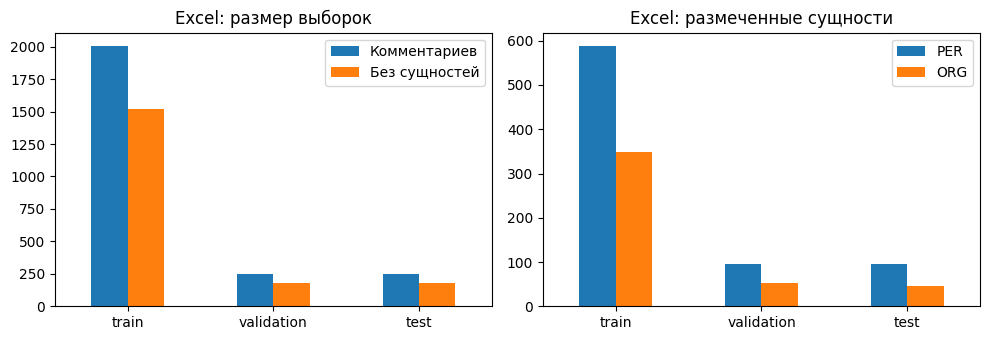

In [3]:
saved_training_info = {'Эпох': 5.0,
 'Лучшая эпоха': 4.0,
 'Validation macro F1': 0.6902293577981651,
 'Время обучения, с': 108.23562137497356}
saved_split_sizes = pd.DataFrame([{'Выборка': 'train',
  'Комментариев': 2008,
  'Без сущностей': 1522,
  'PER': 589,
  'ORG': 348},
 {'Выборка': 'validation',
  'Комментариев': 250,
  'Без сущностей': 180,
  'PER': 96,
  'ORG': 52},
 {'Выборка': 'test',
  'Комментариев': 247,
  'Без сущностей': 182,
  'PER': 95,
  'ORG': 45}]).set_index("Выборка")
display(pd.Series(saved_training_info, name="Значение").round(4).to_frame())
display(saved_split_sizes)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
saved_split_sizes[["Комментариев", "Без сущностей"]].plot.bar(ax=axes[0], rot=0)
saved_split_sizes[["PER", "ORG"]].plot.bar(ax=axes[1], rot=0)
axes[0].set(title="Excel: размер выборок", xlabel="")
axes[1].set(title="Excel: размеченные сущности", xlabel="")
fig.tight_layout()
plt.show()
plt.close(fig)

,PER_precision,PER_recall,PER_f1,ORG_precision,ORG_recall,ORG_f1,f1,macro_f1,PER_char_coverage,ORG_char_coverage,PER_residual_cell_rate,ORG_residual_cell_rate
Исходная,0.6726,0.8000,0.7308,0.0773,0.4000,0.1295,0.3868,0.4301,0.9125,0.8502,0.1951,0.3077
После дообучения,0.8190,0.9053,0.8600,0.3559,0.4667,0.4038,0.7039,0.6319,0.9625,0.7834,0.1220,0.3846


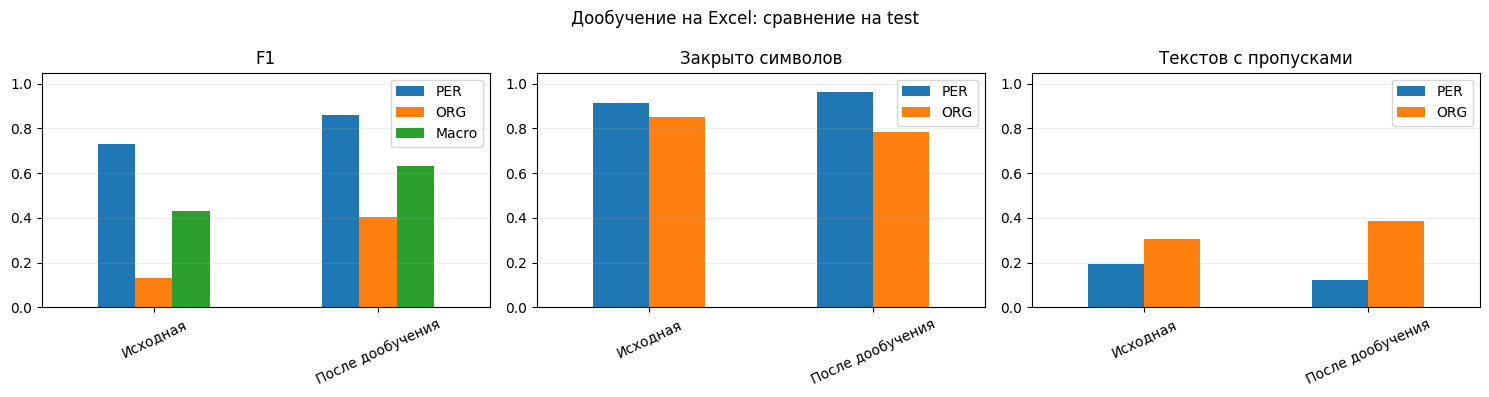

,Эпоха,Train loss,Validation loss,PER F1,ORG F1,Macro F1
0,1.0,0.1673,0.1056,0.8040,0.3559,0.5800
1,2.0,0.0729,0.0779,0.8400,0.4231,0.6315
2,3.0,0.0538,0.0712,0.8400,0.4528,0.6464
3,4.0,0.0462,0.0695,0.8300,0.5505,0.6902
4,5.0,0.0444,0.0690,0.8241,0.5505,0.6873


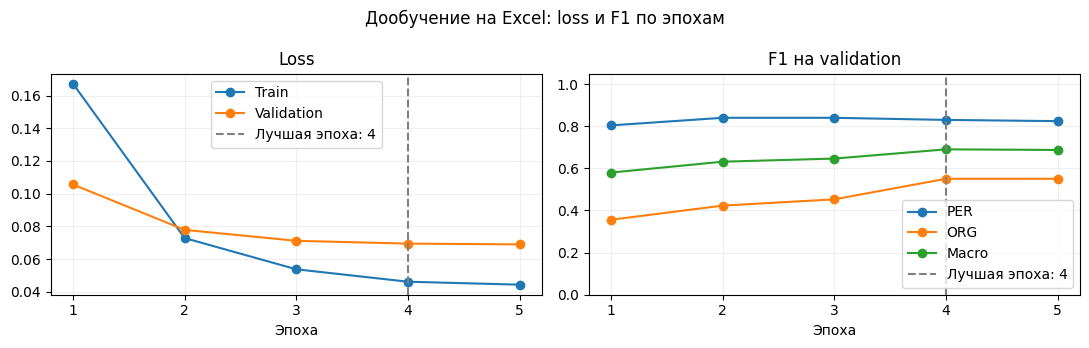

In [4]:
saved_excel_metrics = {'Исходная': {'PER_precision': 0.672566371681416,
              'PER_recall': 0.8,
              'PER_f1': 0.7307692307692307,
              'PER_support': 95,
              'PER_positive_cells': 41,
              'PER_char_coverage': 0.9125,
              'PER_residual_cell_rate': 0.1951219512195122,
              'ORG_precision': 0.07725321888412018,
              'ORG_recall': 0.4,
              'ORG_f1': 0.12949640287769784,
              'ORG_support': 45,
              'ORG_positive_cells': 39,
              'ORG_char_coverage': 0.8501805054151624,
              'ORG_residual_cell_rate': 0.3076923076923077,
              'precision': 0.27167630057803466,
              'recall': 0.6714285714285714,
              'f1': 0.3868312757201646,
              'macro_f1': 0.43013281682346427},
 'После дообучения': {'PER_precision': 0.819047619047619,
                      'PER_recall': 0.9052631578947369,
                      'PER_f1': 0.86,
                      'PER_support': 95,
                      'PER_positive_cells': 41,
                      'PER_char_coverage': 0.9625,
                      'PER_residual_cell_rate': 0.12195121951219512,
                      'ORG_precision': 0.3559322033898305,
                      'ORG_recall': 0.4666666666666667,
                      'ORG_f1': 0.40384615384615385,
                      'ORG_support': 45,
                      'ORG_positive_cells': 39,
                      'ORG_char_coverage': 0.7833935018050542,
                      'ORG_residual_cell_rate': 0.38461538461538464,
                      'precision': 0.6524390243902439,
                      'recall': 0.7642857142857142,
                      'f1': 0.7039473684210527,
                      'macro_f1': 0.6319230769230769}}
saved_excel_history = [{'loss': 0.1673, 'epoch': 1.0, 'step': 129},
 {'eval_loss': 0.10564562678337097,
  'eval_PER_f1': 0.8040201005025126,
  'eval_ORG_f1': 0.3559322033898305,
  'eval_macro_f1': 0.5799761519461716,
  'epoch': 1.0,
  'step': 129},
 {'loss': 0.0729, 'epoch': 2.0, 'step': 258},
 {'eval_loss': 0.07791449129581451,
  'eval_PER_f1': 0.84,
  'eval_ORG_f1': 0.4230769230769231,
  'eval_macro_f1': 0.6315384615384615,
  'epoch': 2.0,
  'step': 258},
 {'loss': 0.0538, 'epoch': 3.0, 'step': 387},
 {'eval_loss': 0.07120965421199799,
  'eval_PER_f1': 0.84,
  'eval_ORG_f1': 0.4528301886792453,
  'eval_macro_f1': 0.6464150943396226,
  'epoch': 3.0,
  'step': 387},
 {'loss': 0.0462, 'epoch': 4.0, 'step': 516},
 {'eval_loss': 0.06949935853481293,
  'eval_PER_f1': 0.83,
  'eval_ORG_f1': 0.5504587155963303,
  'eval_macro_f1': 0.6902293577981651,
  'epoch': 4.0,
  'step': 516},
 {'loss': 0.0444, 'epoch': 5.0, 'step': 645},
 {'eval_loss': 0.06902354955673218,
  'eval_PER_f1': 0.8241206030150754,
  'eval_ORG_f1': 0.5504587155963303,
  'eval_macro_f1': 0.6872896593057028,
  'epoch': 5.0,
  'step': 645},
 {'epoch': 5.0, 'step': 645}]
show_metrics(saved_excel_metrics, "Дообучение на Excel: сравнение на test")
show_training(saved_excel_history, "Дообучение на Excel: loss и F1 по эпохам")

In [ ]:
class AnnotationError(ValueError):
    """Ошибка разметки без содержимого ячеек."""


def parse_annotation(text, raw_json, row_number):
    def fail(reason):
        raise AnnotationError(f"Строка {row_number}: {reason}.")

    if not isinstance(text, str) or not text.strip():
        fail("комментарий должен быть непустым текстом")
    if not isinstance(raw_json, str) or not raw_json.strip():
        fail("нужен JSON; для проверенного текста без сущностей укажите []")
    try:
        annotations = json.loads(raw_json)
    except (ValueError, RecursionError):
        fail("некорректный JSON")
    if not isinstance(annotations, list):
        fail("JSON должен содержать список")
    entities = []
    for item in annotations:
        if not isinstance(item, dict):
            fail("каждая сущность должна быть объектом")
        start, end, kind = (item.get(key) for key in ("start", "end", "label"))
        if type(start) is not int or type(end) is not int:
            fail("start и end должны быть целыми числами")
        if not 0 <= start < end <= len(text):
            fail("позиции сущности выходят за границы комментария")
        if kind not in KINDS:
            fail("допустимы только метки PER и ORG")
        if item.get("text") != text[start:end]:
            fail("text сущности не совпадает с фрагментом по start:end")
        entities.append((start, end, kind))
    entities.sort()
    if any(right[0] < left[1] for left, right in zip(entities, entities[1:])):
        fail("сущности пересекаются или дублируются")
    return entities


def make_sample(text, entities, row_number):
    sample = text_sample(text, sample_id=f"row-{row_number}")
    starts = {start: i for i, (start, _) in enumerate(sample["offsets"])}
    ends = {end: i for i, (_, end) in enumerate(sample["offsets"])}
    for start, end, kind in entities:
        if start not in starts or end not in ends:
            raise AnnotationError(f"Строка {row_number}: граница сущности не совпадает с границей токена.")
        first, last = starts[start], ends[end]
        sample["tags"][first:last + 1] = [f"B-{kind}"] + [f"I-{kind}"] * (last - first)
    return dict(sample, entities=entities)


def normalize_comment(text):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", text)).strip().casefold()


def load_annotations(path, *, sheet_index=0, text_column="Комментарий", status_column="Статус",
                     json_column="Разметка JSON", verified_status="проверено"):
    from openpyxl import load_workbook

    try:
        workbook = load_workbook(path, read_only=True, data_only=False, keep_links=False)
    except Exception:
        raise AnnotationError("Не удалось открыть книгу разметки.") from None
    stats, samples, seen = Counter(), [], {}
    try:
        if not 0 <= sheet_index < len(workbook.worksheets):
            raise AnnotationError("В книге нет листа с указанным номером.")
        rows = workbook.worksheets[sheet_index].iter_rows()
        def normalize_header(value):
            return re.sub(r"\s+", " ", str(value or "")).strip().casefold()
        names = [normalize_header(cell.value) for cell in next(rows, ())]
        required = [normalize_header(name) for name in (text_column, status_column, json_column)]
        settings = ("TEXT_COLUMN", "STATUS_COLUMN", "ANNOTATION_COLUMN")
        columns = (text_column, status_column, json_column)
        for setting, column, name in zip(settings, columns, required):
            count = names.count(name)
            if count != 1:
                reason = "отсутствует" if count == 0 else "повторяется"
                raise AnnotationError(f"Лист {sheet_index + 1}, первая строка: колонка «{column}» {reason}. "
                                      f"Проверьте {setting} и EXCEL_SHEET.")
        if len(set(required)) != 3:
            raise AnnotationError("Колонки текста, статуса и JSON должны различаться.")
        indices = [names.index(name) for name in required]
        for row_number, row in enumerate(rows, 2):
            stats["rows"] += 1
            text_cell, status, json_cell = (row[i] for i in indices)
            if status.data_type == "f":
                raise AnnotationError(f"Строка {row_number}: формула в колонке статуса недопустима.")
            if not isinstance(status.value, str) or status.value.strip().casefold() != verified_status.strip().casefold():
                stats["unverified_skipped"] += 1
                continue
            stats["verified"] += 1
            if "f" in (text_cell.data_type, json_cell.data_type):
                raise AnnotationError(f"Строка {row_number}: вместо комментария или JSON записана формула.")
            text = text_cell.value
            entities = parse_annotation(text, json_cell.value, row_number)
            if text in seen:
                if seen[text] != entities:
                    raise AnnotationError(f"Строка {row_number}: одинаковый комментарий размечен по-разному.")
                stats["duplicates_skipped"] += 1
            else:
                seen[text] = entities
                samples.append(make_sample(text, entities, row_number))
    finally:
        workbook.close()
    if not samples:
        raise AnnotationError("Нет проверенных примеров для обучения.")
    stats.update(unique_samples=len(samples), negative_samples=sum(not sample["entities"] for sample in samples))
    return samples, dict(stats)


def split_samples(samples, *, seed=42, validation_fraction=0.1, test_fraction=0.1):
    if not (0 < validation_fraction < 1 and 0 < test_fraction < 1 and validation_fraction + test_fraction < 1):
        raise AnnotationError("Неверные доли validation/test.")
    groups = defaultdict(list)
    for sample in samples:
        groups[normalize_comment(sample["text"])].append(sample)
    grouped = list(groups.values())
    if len(grouped) < 10:
        raise AnnotationError("Для разделения нужно минимум 10 разных комментариев.")
    n_validation, n_test = (max(1, round(len(grouped) * fraction)) for fraction in (validation_fraction, test_fraction))
    if n_validation + n_test >= len(grouped):
        raise AnnotationError("После разделения не осталось обучающих примеров.")
    rng = random.Random(seed)
    for _ in range(1000):
        rng.shuffle(grouped)
        parts = (grouped[:n_validation], grouped[n_validation:n_validation + n_test], grouped[n_validation + n_test:])
        splits = {name: [sample for group in part for sample in group]
                  for name, part in zip(("validation", "test", "train"), parts)}
        if all({kind for sample in part for _, _, kind in sample["entities"]} == set(KINDS) for part in splits.values()):
            return splits
    raise AnnotationError("Не удалось распределить PER и ORG во все три выборки; "
                          "добавьте разные проверенные комментарии с этими метками или увеличьте доли validation/test.")


def summarize_splits(splits):
    return {name: dict(samples=len(samples), negative_samples=sum(not s["entities"] for s in samples),
                       entities=dict(Counter(kind for s in samples for _, _, kind in s["entities"])))
            for name, samples in splits.items()}

### Загрузка Excel

В разделе 1: `RUN_EXCEL = True`. Путь — `EXCEL_PATH`.
Разделение 80/10/10 фиксировано через `SPLIT_SEED`; одинаковые тексты остаются вместе.

In [ ]:
excel_splits = None
excel_results = []
excel_candidates = []
excel_best = None

if RUN_EXCEL:
    try:
        samples, annotation_counts = load_annotations(EXCEL_PATH, sheet_index=EXCEL_SHEET - 1,
            text_column=TEXT_COLUMN, status_column=STATUS_COLUMN, json_column=ANNOTATION_COLUMN)
        excel_splits = split_samples(samples, seed=SPLIT_SEED)
    except AnnotationError:
        raise
    except Exception:
        raise RuntimeError("Не удалось прочитать Excel-выгрузку.") from None
    split_table = pd.DataFrame(summarize_splits(excel_splits)).T
    split_table["PER"] = [split_table.loc[name, "entities"].get("PER", 0) for name in split_table.index]
    split_table["ORG"] = [split_table.loc[name, "entities"].get("ORG", 0) for name in split_table.index]
    display(split_table.drop(columns="entities"))
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    split_table[["samples", "negative_samples"]].plot.bar(ax=axes[0], rot=0)
    split_table[["PER", "ORG"]].plot.bar(ax=axes[1], rot=0)
    axes[0].set(title="Комментарии", xlabel="")
    axes[1].set(title="Сущности", xlabel="")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

### Текущая модель: validation

Здесь можно увидеть ошибки до нового обучения.

In [ ]:
def count_errors(samples, predictions):
    """Только агрегаты. Категории FN: граница, другой тип, полный пропуск."""
    if len(samples) != len(predictions):
        raise ValueError("Разное число примеров и предсказаний.")
    keys = ("gold", "predicted", "tp", "fp", "fn", "boundary_fn", "wrong_type_fn",
            "missed_fn", "spurious_fp", "negative_comments", "negative_comments_with_fp")
    counts = {kind: Counter({key: 0 for key in keys}) for kind in KINDS}
    for sample, prediction in zip(samples, predictions):
        gold, found = set(sample["entities"]), set(prediction)
        for kind, c in counts.items():
            g = {entity for entity in gold if entity[2] == kind}
            p = {entity for entity in found if entity[2] == kind}
            c.update(gold=len(g), predicted=len(p), tp=len(g & p), fp=len(p - g), fn=len(g - p))
            c["negative_comments"] += int(not gold)
            c["negative_comments_with_fp"] += int(not gold and bool(p))
            for a, b, _ in g - p:
                overlap = [entity for entity in found if entity[0] < b and a < entity[1]]
                category = ("boundary_fn" if any(entity[2] == kind for entity in overlap)
                            else "wrong_type_fn" if overlap else "missed_fn")
                c[category] += 1
            c["spurious_fp"] += sum(not any(x < b and a < y for x, y, _ in gold)
                                    for a, b, _ in p - g)
    return {kind: dict(c) for kind, c in counts.items()}



def inspect_excel_model(path, samples, training):
    model = load_model(path, DEVICE)
    try:
        tokenizer = AutoTokenizer.from_pretrained(path, local_files_only=True, use_fast=True)
        settings = model_settings(path)
        predictions = predict_model(model, tokenizer, samples, batch_size=BATCH_SIZE,
                                    max_length=settings["max_length"], use_column=settings["use_column"])
        return {"metrics": score_spans(samples, predictions), "errors": count_errors(samples, predictions),
                "unseen": unseen_recall(samples, predictions, training)}
    except Exception:
        raise RuntimeError("Не удалось оценить модель на Excel-выгрузке.") from None
    finally:
        del model
        release_model()

In [ ]:
if excel_splits is not None:
    excel_candidates = []
    for name, checkpoint in [("Исходная", MODEL_DIR), ("Текущая", CURRENT_MODEL_DIR)]:
        check = inspect_excel_model(checkpoint, excel_splits["validation"], excel_splits["train"])
        excel_candidates.append({"name": name, "variant": name, "seed": None,
                                 "model_path": str(checkpoint), "metrics": check["metrics"]})
        if name == "Текущая":
            current_errors = pd.DataFrame(check["errors"]).T
            current_unseen = pd.DataFrame(check["unseen"])
    show_metrics({row["name"]: row["metrics"] for row in excel_candidates}, "Excel: validation")
    display(current_errors)
    display(current_unseen.round(4))
    fig, ax = plt.subplots(figsize=(8, 3.5))
    error_plot = current_errors[["boundary_fn", "wrong_type_fn", "missed_fn", "fp"]].copy()
    error_plot.columns = ["Границы", "Другой тип", "Пропуск", "Ложное выделение"]
    error_plot.plot.bar(ax=ax, rot=0)
    ax.set(title="Ошибки текущей модели на validation", xlabel="", ylabel="Сущностей")
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    excel_best = max(excel_candidates, key=lambda row: row["metrics"]["macro_f1"])

### Обучение и сравнение

`TRAIN_EXCEL = True` — один режим с `EXCEL_LR` и `EXCEL_EPOCHS`.
`SEARCH_PARAMS = True` — прежний режим, три learning rate и вес ORG 1.5.
Для повторов задайте `TRAIN_SEEDS = [42, 43, 44]`. Test здесь не используется.

In [ ]:
if excel_splits is not None and (TRAIN_EXCEL or SEARCH_PARAMS):
    excel_results = []
    excel_candidates = [row for row in excel_candidates if row["seed"] is None]
    run_dir = ROOT / "runs" / ("excel_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
    configs = [("control", EXCEL_LR, EXCEL_EPOCHS, None)]
    if SEARCH_PARAMS:
        configs += [(f"lr{lr:.0e}", lr, SEARCH_EPOCHS, None) for lr in SEARCH_LRS]
        configs += [("org_weight1_5", EXCEL_LR, SEARCH_EPOCHS, {"B-ORG": 1.5, "I-ORG": 1.5})]
    settings = model_settings(MODEL_DIR)
    if settings["use_column"]:
        raise ValueError("Для Excel нужна модель без префикса колонки.")
    train_tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR, local_files_only=True, use_fast=True)
    try:
        for variant, lr, epochs, weights in configs:
            for seed in TRAIN_SEEDS:
                name = f"{variant}_seed{seed}"
                result = train_experiment(name, MODEL_DIR, train_tokenizer,
                    excel_splits["train"], excel_splits["validation"], run_dir, device=DEVICE,
                    lr=lr, epochs=epochs, seed=seed, max_length=settings["max_length"],
                    batch_size=BATCH_SIZE, gradient_accumulation_steps=ACCUMULATION, class_weights=weights)
                excel_results.append(result)
                excel_candidates.append({"name": name, "variant": variant, "seed": seed,
                                         "model_path": result["model_path"], "metrics": result["validation"]})
    except Exception:
        raise RuntimeError("Не удалось дообучить модель. Проверьте параметры и ядро .venv.") from None

In [ ]:
if excel_candidates:
    scores = pd.DataFrame([{"name": row["name"], "variant": row["variant"],
                            "macro_f1": row["metrics"]["macro_f1"]} for row in excel_candidates])
    ranking = scores.groupby("variant")["macro_f1"].agg(["mean", "std", "count"]).fillna(0)
    ranking = ranking.sort_values("mean", ascending=False)
    display(ranking.round(4))
    best_variant = ranking.index[0]
    group = [row for row in excel_candidates if row["variant"] == best_variant]
    median = float(np.median([row["metrics"]["macro_f1"] for row in group]))
    excel_best = min(group, key=lambda row: abs(row["metrics"]["macro_f1"] - median))
    display(pd.DataFrame([{"Выбрана модель": excel_best["name"], "Папка весов": excel_best["model_path"]}]))
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.bar(ranking.index, ranking["mean"], yerr=ranking["std"], capsize=4)
    ax.set(title="Macro F1 на validation: среднее и разброс по seed", ylim=(0, 1.05), ylabel="F1")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    if excel_results:
        show_metrics({row["name"]: row["metrics"] for row in excel_candidates}, "Excel: сравнение на validation")
        selected_training = next((row for row in excel_results if row["model_path"] == excel_best["model_path"]), None)
        if selected_training is None:
            selected_training = max(excel_results, key=lambda row: row["validation"]["macro_f1"])
        show_training(selected_training["training_history"], "Дообучение на Excel: " + selected_training["method"])

### Финальный test

Когда выбор закончен, включите `RUN_TEST = True` и выполните только следующую ячейку.
Она использует то же разделение из памяти. По test параметры не подбираем.
Смотрите ORG F1, precision, покрытие и пропуски; PER тоже не должен ухудшиться.

In [ ]:
if RUN_TEST:
    if excel_splits is None or excel_best is None:
        raise ValueError("Сначала выполните загрузку Excel и сравнение на validation.")
    test_metrics = {}
    for name, checkpoint in [("Исходная", MODEL_DIR), ("Текущая", CURRENT_MODEL_DIR),
                             ("Выбранная", excel_best["model_path"])]:
        check = inspect_excel_model(checkpoint, excel_splits["test"], excel_splits["train"])
        test_metrics[name] = check["metrics"]
    show_metrics(test_metrics, "Excel: финальный test")

## 9. Маскировка текста

Ниже вымышленные примеры. При работе с Excel используется выбранная модель.

In [ ]:
EMAIL_RE = re.compile('(?<![\\w.+-])[\\w.+-]+@(?:[\\w-]+\\.)+[\\w-]{2,}(?![\\w-])')
PHONE_RE = re.compile('(?<!\\w)(?:\\+?7|8)[\\s().-]*\\d{3}[\\s().-]*\\d{3}[\\s.-]*\\d{2}[\\s.-]*\\d{2}(?!\\w)')

def merge_mask_spans(spans):
    merged = []
    for a, b, kind in sorted(set(spans), key=lambda x: (x[0], -x[1], x[2])):
        if merged and a < merged[-1][1]:
            x, y, previous = merged[-1]
            merged[-1] = (x, max(y, b), previous if previous == kind else "СКРЫТО")
        else:
            merged.append((a, b, kind))
    return merged


def mask_spans(text, spans):
    pieces, cursor = [], 0
    for a, b, kind in merge_mask_spans(spans):
        if not (0 <= a < b <= len(text)):
            raise ValueError("Некорректные координаты для маскировки.")
        pieces.extend((text[cursor:a], f"[{kind}]"))
        cursor = b
    pieces.append(text[cursor:])
    return "".join(pieces)


class Masker:
    """Модель ищет людей и компании, правила — почту и телефоны."""
    def __init__(self, model, tokenizer, use_column=False, max_length=128, batch_size=16):
        check_model_labels(model)
        self.model, self.tokenizer = model, tokenizer
        self.use_column, self.max_length, self.batch_size = use_column, max_length, batch_size

    def __call__(self, text, column=""):
        sample = text_sample(text, column)
        spans = predict_model(self.model, self.tokenizer, [sample], self.max_length,
                              self.batch_size, self.use_column)[0]
        for regex, kind in ((EMAIL_RE, "EMAIL"), (PHONE_RE, "PHONE")):
            spans.extend((m.start(), m.end(), kind) for m in regex.finditer(text))
        return mask_spans(text, spans)

In [ ]:
if excel_best is not None:
    active_model_dir = Path(excel_best["model_path"])
    del model
    release_model()
    settings = model_settings(active_model_dir)
    tokenizer = AutoTokenizer.from_pretrained(active_model_dir, local_files_only=True, use_fast=True)
    model = load_model(active_model_dir, "cpu")

In [ ]:
masker = Masker(model, tokenizer, max_length=settings["max_length"],
                use_column=settings["use_column"], batch_size=1)
examples = [
    "Иван Петров работает в Газпром. Напишите ivan@example.org.",
    "ИП Процентко: телефон +7 (999) 123-45-67.",
    "Оплата получена, доставка завтра после обеда.",
]
display(pd.DataFrame({"Исходный текст": examples, "После замены": [masker(t) for t in examples]}))

## 10. Маскировка файла Excel

Результат сохраняется в новую книгу. Исходный файл не меняется.
Оформление, ссылки и комментарии не переносятся, формулы заменяются на `[ФОРМУЛА]`.
CSV оставлен как дополнительный формат.

In [ ]:
def check_output(input_path, output_path, suffix):
    source, target = Path(input_path).expanduser().resolve(), Path(output_path).expanduser().resolve()
    if source.suffix.lower() != suffix or target.suffix.lower() != suffix:
        raise ValueError(f"Ожидаются файлы {suffix}.")
    if source == target or target.exists():
        raise FileExistsError("Выберите новое имя: существующие файлы не перезаписываются.")
    if not source.is_file():
        raise FileNotFoundError(source)
    return source, target


def safe_csv_text(value):
    # Апостроф не даёт Excel принять текст за формулу.
    return "'" + value if value.lstrip().startswith(("=", "+", "-", "@")) else value


def mask_csv(input_path, output_path, masker, delimiter=";", encoding="utf-8-sig", header=True):
    source, target = check_output(input_path, output_path, ".csv")
    if len(delimiter) != 1:
        raise ValueError("delimiter должен быть одним символом.")
    stats = {"rows": 0, "changed_cells": 0}
    with source.open(encoding=encoding, newline="") as stream:
        reader = csv.reader(stream, delimiter=delimiter)
        columns = next(reader, []) if header else []
        with target.open("x", encoding=encoding, newline="") as result:
            try:
                writer = csv.writer(result, delimiter=delimiter)
                if header:
                    writer.writerow([safe_csv_text(masker(c)) for c in columns])
                for row in reader:
                    output = []
                    for i, text in enumerate(row):
                        masked = masker(text, columns[i] if i < len(columns) else "")
                        stats["changed_cells"] += masked != text
                        output.append(safe_csv_text(masked))
                    writer.writerow(output)
                    stats["rows"] += 1
            except BaseException:
                result.close()
                target.unlink(missing_ok=True)
                raise
    return stats

In [ ]:
def mask_xlsx(input_path, output_path, masker, header_row=1):
    """Сохраняем значения всех листов в новую книгу."""
    from openpyxl import Workbook, load_workbook
    source_path, target_path = check_output(input_path, output_path, ".xlsx")
    if header_row is not None and (type(header_row) is not int or header_row < 1):
        raise ValueError("header_row: положительное число либо None.")
    source = load_workbook(source_path, read_only=True, data_only=False, keep_links=False)
    result = Workbook()
    result.remove(result.active)
    report = []
    try:
        for index, sheet in enumerate(source.worksheets, 1):
            output = result.create_sheet(f"Sheet_{index}")
            columns = {}
            if header_row is not None:
                columns = {c.column: str(c.value) for c in sheet[header_row] if c.value is not None and c.data_type != "f"}
            stats = {"sheet": output.title, "nonempty_cells": 0, "changed_cells": 0, "formulas_removed": 0}
            for row in sheet.iter_rows():
                for cell in row:
                    value = cell.value
                    if value is None:
                        continue
                    stats["nonempty_cells"] += 1
                    if cell.data_type == "f":
                        masked = "[ФОРМУЛА]"
                        stats["formulas_removed"] += 1
                    elif isinstance(value, (str, int, float)) and not isinstance(value, bool):
                        text = str(int(value)) if isinstance(value, float) and value.is_integer() else str(value)
                        column = columns.get(cell.column, "") if header_row is not None and cell.row > header_row else ""
                        transformed = masker(text, column)
                        masked = transformed if transformed != text else value
                        stats["changed_cells"] += transformed != text
                    else:
                        masked = value
                    output_cell = output.cell(cell.row, cell.column, masked)
                    if isinstance(masked, str):
                        output_cell.data_type = "s"
            report.append(stats)
    finally:
        source.close()
    with target_path.open("xb") as stream:
        try:
            result.save(stream)
        except BaseException:
            stream.close()
            target_path.unlink(missing_ok=True)
            raise
    return report

In [ ]:
# Укажите свои пути и раскомментируйте нужную строку.
# display(pd.DataFrame(mask_xlsx(ROOT / "export.xlsx", ROOT / "export_masked.xlsx", masker)))
# display(pd.Series(mask_csv(ROOT / "export.csv", ROOT / "export_masked.csv", masker)))